In [3]:
   # AirCast: Predicting Urban Air Quality (PM2.5)
   ## 1. Dataset documentation
   ## 2. EDA
   ## 3. Visualisation
   ## 4. Outlier detection
   ## 5. Feature engineering and models
   ## 6. Evaluation
   ## 7. Error analysis and interpretation
   ## 8. Written reflection

In [4]:
import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns


In [5]:
import os
for folder, subfolders, filenames in os.walk('/kaggle/input'):
    for name in filenames:
        print(os.path.join(folder, name))

/kaggle/input/PRSA_Data_Aotizhongxin_20130301-20170228.csv
/kaggle/input/PRSA_Data_Changping_20130301-20170228.csv
/kaggle/input/PRSA_Data_Dingling_20130301-20170228.csv
/kaggle/input/PRSA_Data_Dongsi_20130301-20170228.csv
/kaggle/input/PRSA_Data_Guanyuan_20130301-20170228.csv
/kaggle/input/PRSA_Data_Gucheng_20130301-20170228.csv
/kaggle/input/PRSA_Data_Huairou_20130301-20170228.csv
/kaggle/input/PRSA_Data_Nongzhanguan_20130301-20170228.csv
/kaggle/input/PRSA_Data_Shunyi_20130301-20170228.csv
/kaggle/input/PRSA_Data_Tiantan_20130301-20170228.csv
/kaggle/input/PRSA_Data_Wanliu_20130301-20170228.csv
/kaggle/input/PRSA_Data_Wanshouxigong_20130301-20170228.csv


In [6]:
df = pd.read_csv('/kaggle/input/PRSA_Data_Aotizhongxin_20130301-20170228.csv')
df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [7]:
df.shape



(35064, 18)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
No         35064 non-null int64
year       35064 non-null int64
month      35064 non-null int64
day        35064 non-null int64
hour       35064 non-null int64
PM2.5      34139 non-null float64
PM10       34346 non-null float64
SO2        34129 non-null float64
NO2        34041 non-null float64
CO         33288 non-null float64
O3         33345 non-null float64
TEMP       35044 non-null float64
PRES       35044 non-null float64
DEWP       35044 non-null float64
RAIN       35044 non-null float64
wd         34983 non-null object
WSPM       35050 non-null float64
station    35064 non-null object
dtypes: float64(11), int64(5), object(2)
memory usage: 4.8+ MB


In [9]:
(df.isna().mean() * 100).round(2)

No         0.00
year       0.00
month      0.00
day        0.00
hour       0.00
PM2.5      2.64
PM10       2.05
SO2        2.67
NO2        2.92
CO         5.07
O3         4.90
TEMP       0.06
PRES       0.06
DEWP       0.06
RAIN       0.06
wd         0.23
WSPM       0.04
station    0.00
dtype: float64

In [10]:
df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])
df[['datetime', 'PM2.5']].head()

,datetime,PM2.5
0,2013-03-01 00:00:00,4.0
1,2013-03-01 01:00:00,8.0
2,2013-03-01 02:00:00,7.0
3,2013-03-01 03:00:00,6.0
4,2013-03-01 04:00:00,3.0


In [11]:
print(df['datetime'].min())
print(df['datetime'].max())

2013-03-01 00:00:00
2017-02-28 23:00:00


In [12]:
df.describe().round(2)

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,35064.00,35064.00,35064.00,35064.00,35064.00,34139.00,34346.00,34129.00,34041.00,33288.00,33345.00,35044.00,35044.00,35044.00,35044.00,35050.00
mean,17532.50,2014.66,6.52,15.73,11.50,82.77,110.06,17.38,59.31,1262.95,56.35,13.58,1011.85,3.12,0.07,1.71
std,10122.25,1.18,3.45,8.80,6.92,82.14,95.22,22.82,37.12,1221.44,57.92,11.40,10.40,13.69,0.91,1.20
min,1.00,2013.00,1.00,1.00,0.00,3.00,2.00,0.29,2.00,100.00,0.21,-16.80,985.90,-35.30,0.00,0.00
25%,8766.75,2014.00,4.00,8.00,5.75,22.00,38.00,3.00,30.00,500.00,8.00,3.10,1003.30,-8.10,0.00,0.90
50%,17532.50,2015.00,7.00,16.00,11.50,58.00,87.00,9.00,53.00,900.00,42.00,14.50,1011.40,3.80,0.00,1.40
75%,26298.25,2016.00,10.00,23.00,17.25,114.00,155.00,21.00,82.00,1500.00,82.00,23.30,1020.10,15.60,0.00,2.20
max,35064.00,2017.00,12.00,31.00,23.00,898.00,984.00,341.00,290.00,10000.00,423.00,40.50,1042.00,28.50,72.50,11.20


In [13]:
print("Negative PM2.5:", (df['PM2.5'] < 0).sum())
print("Zero PM2.5:", (df['PM2.5'] == 0).sum())
print("Negative wind speed:", (df['WSPM'] < 0).sum())
print("PM2.5 above 500:", (df['PM2.5'] > 500).sum())


Negative PM2.5: 0
Zero PM2.5: 0
Negative wind speed: 0
PM2.5 above 500: 76


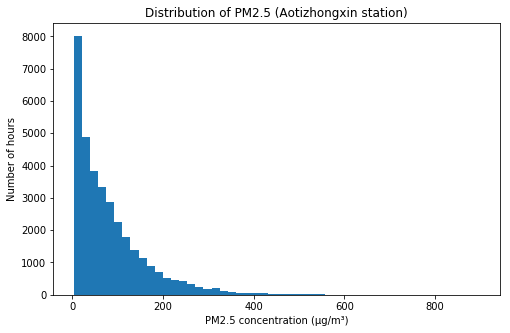

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(df['PM2.5'].dropna(), bins=50)
plt.title('Distribution of PM2.5 (Aotizhongxin station)')
plt.xlabel('PM2.5 concentration (µg/m³)')
plt.ylabel('Number of hours')
plt.savefig('pm25_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

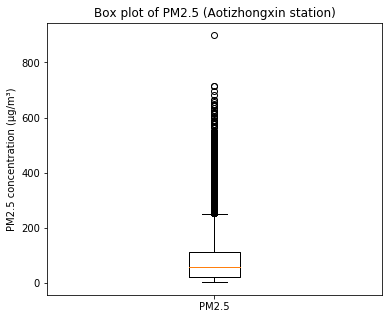

In [15]:
plt.figure(figsize=(6, 5))
plt.boxplot(df['PM2.5'].dropna())
plt.title('Box plot of PM2.5 (Aotizhongxin station)')
plt.ylabel('PM2.5 concentration (µg/m³)')
plt.xticks([1], ['PM2.5'])
plt.savefig('pm25_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

/opt/conda/lib/python3.6/site-packages/pandas/plotting/_matplotlib/converter.py:103: FutureWarning: Using an implicitly registered datetime converter for a matplotlib plotting method. The converter was registered by pandas on import. Future versions of pandas will require you to explicitly register matplotlib converters.

To register the converters:
	>>> from pandas.plotting import register_matplotlib_converters
	>>> register_matplotlib_converters()
  warnings.warn(msg, FutureWarning)


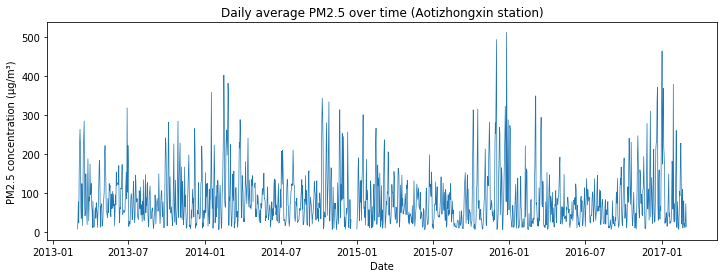

In [16]:
daily = df.set_index('datetime')['PM2.5'].resample('D').mean()

plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily.values, linewidth=0.7)
plt.title('Daily average PM2.5 over time (Aotizhongxin station)')
plt.xlabel('Date')
plt.ylabel('PM2.5 concentration (µg/m³)')
plt.savefig('pm25_over_time.png', dpi=150, bbox_inches='tight')
plt.show()

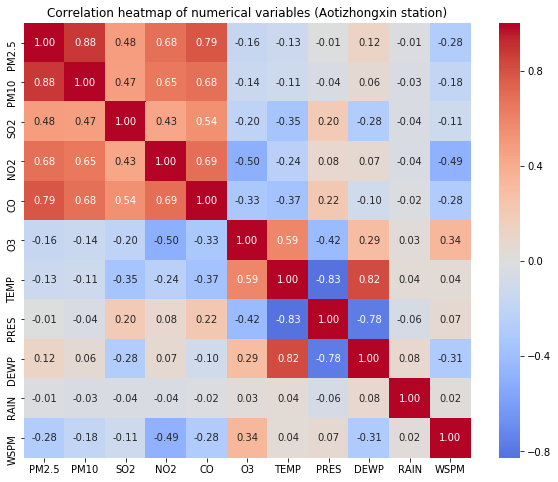

In [17]:
cols = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3',
        'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']

corr = df[cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap of numerical variables (Aotizhongxin station)')
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

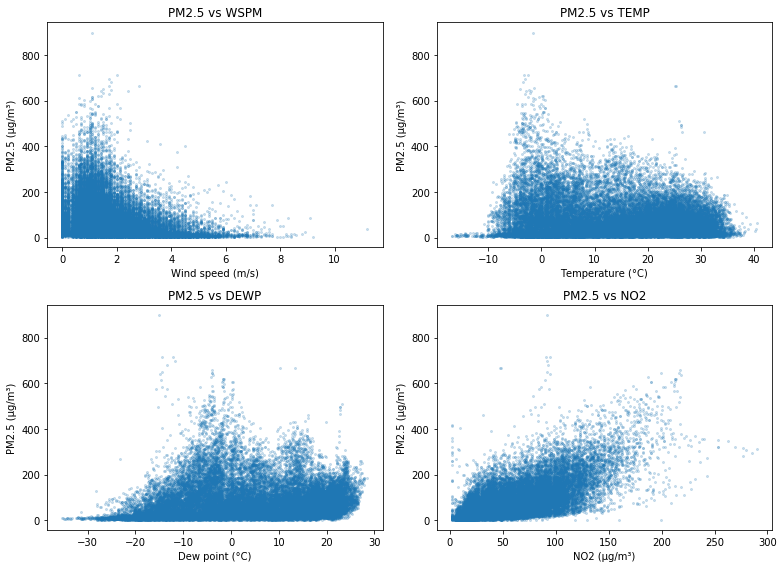

In [18]:
variables = ['WSPM', 'TEMP', 'DEWP', 'NO2']
labels = {'WSPM': 'Wind speed (m/s)', 'TEMP': 'Temperature (°C)',
          'DEWP': 'Dew point (°C)', 'NO2': 'NO2 (µg/m³)'}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, v in zip(axes.flatten(), variables):
    ax.scatter(df[v], df['PM2.5'], s=4, alpha=0.2)
    ax.set_title('PM2.5 vs ' + v)
    ax.set_xlabel(labels[v])
    ax.set_ylabel('PM2.5 (µg/m³)')

plt.tight_layout()
plt.savefig('feature_scatterplots.png', dpi=150, bbox_inches='tight')
plt.show()

In [19]:
pm = df['PM2.5'].dropna()

Q1 = pm.quantile(0.25)
Q3 = pm.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

iqr_flag = (df['PM2.5'] < lower) | (df['PM2.5'] > upper)

print("Q1:", Q1, " Q3:", Q3, " IQR:", IQR)
print("Lower fence:", lower, " Upper fence:", upper)
print("IQR outliers:", iqr_flag.sum())


Q1: 22.0  Q3: 114.0  IQR: 92.0
Lower fence: -116.0  Upper fence: 252.0
IQR outliers: 1624


In [20]:
mean = pm.mean()
std = pm.std()

z = (df['PM2.5'] - mean) / std
z_flag = z.abs() > 3

print("Mean:", round(mean, 2), " Std:", round(std, 2))
print("Z-score outliers:", z_flag.sum())

Mean: 82.77  Std: 82.14
Z-score outliers: 591


In [21]:
both = (iqr_flag & z_flag).sum()
only_iqr = (iqr_flag & ~z_flag).sum()
only_z = (~iqr_flag & z_flag).sum()

print("Flagged by both:", both)
print("Only IQR:", only_iqr)
print("Only Z-score:", only_z)

Flagged by both: 591
Only IQR: 1033
Only Z-score: 0


In [22]:
flagged = df[iqr_flag]
flagged['month'].value_counts().sort_index()

1     192
2     195
3     243
4      17
5      29
6      36
7      13
8       2
9      21
10    296
11    222
12    358
Name: month, dtype: int64

In [23]:
check_cols = ['PM10', 'NO2', 'CO', 'WSPM', 'TEMP']
rows = []

for c in check_cols:
    s = df[c].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    i = q3 - q1
    iqr_n = ((df[c] < q1 - 1.5 * i) | (df[c] > q3 + 1.5 * i)).sum()
    z_n = (((df[c] - s.mean()) / s.std()).abs() > 3).sum()
    rows.append([c, iqr_n, z_n])

pd.DataFrame(rows, columns=['Variable', 'IQR outliers', 'Z-score outliers'])

,Variable,IQR outliers,Z-score outliers
0,PM10,1080,508
1,NO2,472,326
2,CO,2607,741
3,WSPM,1742,500
4,TEMP,0,0


In [24]:
import glob

files = sorted(glob.glob('/kaggle/input/*.csv'))
df_all = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
df_all['datetime'] = pd.to_datetime(df_all[['year', 'month', 'day', 'hour']])

print(df_all.shape)
df_all.groupby('station')['PM2.5'].agg(['count', 'mean', 'median', 'max']).round(1)

(420768, 19)


,count,mean,median,max
station,,,,
Aotizhongxin,34139,82.8,58.0,898.0
Changping,34290,71.1,46.0,882.0
Dingling,34285,66.0,41.0,881.0
Dongsi,34314,86.2,61.0,737.0
Guanyuan,34448,82.9,59.0,680.0
Gucheng,34418,83.9,60.0,770.0
Huairou,34111,69.6,47.0,762.0
Nongzhanguan,34436,84.8,59.0,844.0
Shunyi,34151,79.5,55.0,941.0


In [25]:
print("Duplicate rows:", df_all.duplicated().sum())
print("Duplicate station+hour:", df_all.duplicated(subset=['station', 'datetime']).sum())
print("PM2.5 > PM10 (implausible):", (df_all['PM2.5'] > df_all['PM10']).sum())

Duplicate rows: 0
Duplicate station+hour: 0
PM2.5 > PM10 (implausible): 21312


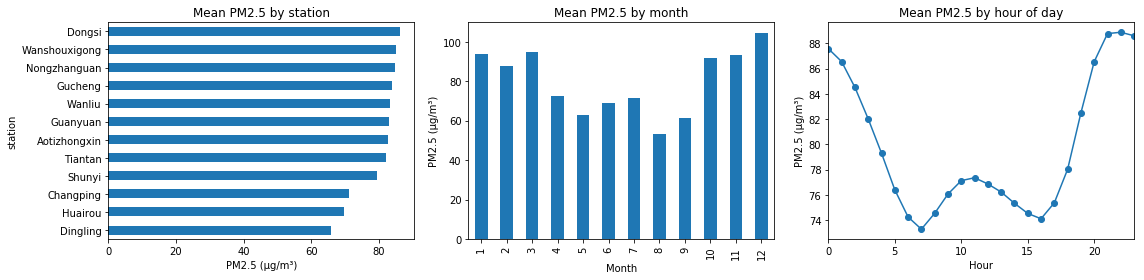

In [26]:
station_mean = df_all.groupby('station')['PM2.5'].mean().sort_values()
monthly = df_all.groupby('month')['PM2.5'].mean()
hourly = df_all.groupby('hour')['PM2.5'].mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

station_mean.plot(kind='barh', ax=axes[0])
axes[0].set_title('Mean PM2.5 by station')
axes[0].set_xlabel('PM2.5 (µg/m³)')

monthly.plot(kind='bar', ax=axes[1])
axes[1].set_title('Mean PM2.5 by month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('PM2.5 (µg/m³)')

hourly.plot(ax=axes[2], marker='o')
axes[2].set_title('Mean PM2.5 by hour of day')
axes[2].set_xlabel('Hour')
axes[2].set_ylabel('PM2.5 (µg/m³)')

plt.tight_layout()
plt.savefig('pm25_patterns.png', dpi=150, bbox_inches='tight')
plt.show()

In [27]:
df_all = df_all.sort_values(['station', 'datetime']).reset_index(drop=True)

train = df_all[df_all['datetime'] < '2015-03-01'].copy()
val = df_all[(df_all['datetime'] >= '2015-03-01') & (df_all['datetime'] < '2016-03-01')].copy()
test = df_all[df_all['datetime'] >= '2016-03-01'].copy()

print(len(train), len(val), len(test))
SEED=42

210240 105408 105120


In [28]:
for d in [train, val, test]:
    d['hour_sin'] = np.sin(2 * np.pi * d['hour'] / 24)
    d['hour_cos'] = np.cos(2 * np.pi * d['hour'] / 24)
    d['month_sin'] = np.sin(2 * np.pi * d['month'] / 12)
    d['month_cos'] = np.cos(2 * np.pi * d['month'] / 12)
    d['dayofweek'] = d['datetime'].dt.dayofweek
    d['is_heating_season'] = d['month'].isin([11, 12, 1, 2, 3]).astype(int)

train[['datetime', 'hour', 'hour_sin', 'hour_cos', 'is_heating_season']].head()

,datetime,hour,hour_sin,hour_cos,is_heating_season
0,2013-03-01 00:00:00,0,0.000000,1.000000,1
1,2013-03-01 01:00:00,1,0.258819,0.965926,1
2,2013-03-01 02:00:00,2,0.500000,0.866025,1
3,2013-03-01 03:00:00,3,0.707107,0.707107,1
4,2013-03-01 04:00:00,4,0.866025,0.500000,1


In [29]:
target = 'PM2.5'
num_features = ['TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM',
                'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
                'dayofweek', 'is_heating_season']
cat_features = ['wd', 'station']

train_m = train.dropna(subset=[target])
val_m = val.dropna(subset=[target])
test_m = test.dropna(subset=[target])

X_train, y_train = train_m[num_features + cat_features], train_m[target]
X_val, y_val = val_m[num_features + cat_features], val_m[target]
X_test, y_test = test_m[num_features + cat_features], test_m[target]

print(len(X_train), len(X_val), len(X_test))

205989 103287 102753


## Feature engineering notes (D4)

| Feature | Calculation | Why it may help |
|---|---|---|
| `hour_sin`, `hour_cos` | sin/cos of 2π × hour / 24 | Captures the daily pollution cycle; hour 23 and hour 0 become neighbours |
| `month_sin`, `month_cos` | sin/cos of 2π × month / 12 | Captures seasonality; December and January become neighbours |
| `is_heating_season` | 1 if month is Nov-Mar, else 0 | Winter heating raises emissions |
| `dayofweek` | Monday = 0 ... Sunday = 6 | Traffic can differ on weekends |

**No future information used:** every feature is computed only from the row's own timestamp, with no PM2.5 values, lags or later observations. The data was split by date, and the imputer, scaler and encoder were fitted on the training set only.

**Result:** month features were the most useful. Hour added little, and `is_heating_season` and `dayofweek` added almost nothing.

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])
cat_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

prep = ColumnTransformer([
    ('num', num_pipe, num_features),
    ('cat', cat_pipe, cat_features)
])

In [31]:
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(model, X, y):
    pred = model.predict(X)
    mae = mean_absolute_error(y, pred)
    mse = mean_squared_error(y, pred)
    return {'MAE': round(mae, 2), 'MSE': round(mse, 1),
            'RMSE': round(np.sqrt(mse), 2), 'R2': round(r2_score(y, pred), 3)}

mean_model = Pipeline([('prep', prep), ('model', DummyRegressor(strategy='mean'))])
lin_model = Pipeline([('prep', prep), ('model', LinearRegression())])

mean_model.fit(X_train, y_train)
lin_model.fit(X_train, y_train)

print("Mean-only:", evaluate(mean_model, X_val, y_val))
print("Linear train:", evaluate(lin_model, X_train, y_train))
print("Linear val:", evaluate(lin_model, X_val, y_val))

Mean-only: {'MAE': 61.01, 'MSE': 6823.5, 'RMSE': 82.6, 'R2': -0.018}
Linear train: {'MAE': 45.36, 'MSE': 3838.4, 'RMSE': 61.96, 'R2': 0.386}
Linear val: {'MAE': 48.24, 'MSE': 4527.5, 'RMSE': 67.29, 'R2': 0.325}


In [32]:
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    'Linear Regression': LinearRegression(),
    'Ridge (alpha=1)': Ridge(alpha=1.0),
    'Decision Tree (depth 8)': DecisionTreeRegressor(max_depth=8, min_samples_leaf=50, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=20,
                                           n_jobs=-1, random_state=42),
}

fitted = {}
rows = []
for name, m in models.items():
    pipe = Pipeline([('prep', prep), ('model', m)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    tr = evaluate(pipe, X_train, y_train)
    va = evaluate(pipe, X_val, y_val)
    rows.append([name, tr['MAE'], va['MAE'], va['MSE'], va['RMSE'], tr['R2'], va['R2']])

results = pd.DataFrame(rows, columns=['Model', 'Train MAE', 'Val MAE', 'Val MSE',
                                      'Val RMSE', 'Train R2', 'Val R2'])
results

,Model,Train MAE,Val MAE,Val MSE,Val RMSE,Train R2,Val R2
0,Linear Regression,45.36,48.24,4527.5,67.29,0.386,0.325
1,Ridge (alpha=1),45.36,48.24,4527.5,67.29,0.386,0.325
2,Decision Tree (depth 8),40.30,45.39,4764.5,69.03,0.474,0.289
3,Random Forest,24.89,44.28,4624.8,68.01,0.779,0.310


In [33]:
rf_rows = []
for depth, leaf in [(6, 200), (10, 100), (15, 20)]:
    rf = Pipeline([('prep', prep),
                   ('model', RandomForestRegressor(n_estimators=50, max_depth=depth,
                                                   min_samples_leaf=leaf, max_features=0.5,
                                                   n_jobs=-1, random_state=SEED))])
    rf.fit(X_train, y_train)
    tr = evaluate(rf, X_train, y_train)
    va = evaluate(rf, X_val, y_val)
    rf_rows.append([depth, leaf, tr['R2'], va['R2'], va['RMSE'], va['MAE']])

pd.DataFrame(rf_rows, columns=['max_depth', 'min_samples_leaf', 'Train R2', 'Val R2', 'Val RMSE', 'Val MAE'])

,max_depth,min_samples_leaf,Train R2,Val R2,Val RMSE,Val MAE
0,6,200,0.400,0.322,67.41,46.71
1,10,100,0.564,0.375,64.72,43.48
2,15,20,0.753,0.360,65.50,43.07


In [34]:
from sklearn.linear_model import Lasso

lasso = Pipeline([('prep', prep), ('model', Lasso(alpha=0.1, max_iter=5000))])
lasso.fit(X_train, y_train)

print("Lasso train:", evaluate(lasso, X_train, y_train))
print("Lasso val:", evaluate(lasso, X_val, y_val))

ohe=lasso.named_steps['prep'].named_transformers_['cat'].named_steps['onehot']
names = np.array(num_features+list(ohe.get_feature_names(cat_features)))
coefs = lasso.named_steps['model'].coef_
print("Features kept:", (coefs != 0).sum(), "of", len(coefs))
print("Zeroed out:", list(names[coefs == 0]))

Lasso train: {'MAE': 45.36, 'MSE': 3842.8, 'RMSE': 61.99, 'R2': 0.385}
Lasso val: {'MAE': 48.15, 'MSE': 4528.2, 'RMSE': 67.29, 'R2': 0.325}
Features kept: 32 of 39
Zeroed out: ['wd_N', 'wd_NNE', 'wd_NNW', 'wd_SSW', 'wd_WNW', 'station_Gucheng', 'station_Shunyi']


In [35]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate

tv = pd.concat([train_m, val_m]).sort_values('datetime', kind='stable')
X_tv, y_tv = tv[num_features + cat_features], tv[target]

tscv = TimeSeriesSplit(n_splits=4)

cv_models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=50, max_depth=10, min_samples_leaf=100,
                                           max_features=0.5, n_jobs=-1, random_state=SEED),
}

for name, m in cv_models.items():
    pipe = Pipeline([('prep', prep), ('model', m)])
    s = cross_validate(pipe, X_tv, y_tv, cv=tscv,
                       scoring=['r2', 'neg_mean_absolute_error'])
    print(name)
    print("  R2 per fold:", s['test_r2'].round(3), " mean:", s['test_r2'].mean().round(3))
    print("  MAE per fold:", (-s['test_neg_mean_absolute_error']).round(1),
          " mean:", (-s['test_neg_mean_absolute_error']).mean().round(1))

Linear Regression
  R2 per fold: [0.324 0.38  0.301 0.347]  mean: 0.338
  MAE per fold: [52.2 40.7 44.5 54.3]  mean: 47.9
Random Forest
  R2 per fold: [0.014 0.335 0.403 0.394]  mean: 0.286
  MAE per fold: [57.1 42.9 38.2 49.3]  mean: 46.9


In [36]:
all_models = dict(fitted)
all_models['Lasso'] = lasso
all_models['Mean-only baseline'] = mean_model

best_rf = Pipeline([('prep', prep),
                    ('model', RandomForestRegressor(n_estimators=50, max_depth=10, min_samples_leaf=100,
                                                    max_features=0.5, n_jobs=-1, random_state=SEED))])
best_rf.fit(X_train, y_train)
all_models['Random Forest (tuned)'] = best_rf

rows = []
for name, m in all_models.items():
    va = evaluate(m, X_val, y_val)
    te = evaluate(m, X_test, y_test)
    rows.append([name, va['RMSE'], va['R2'], te['MAE'], te['MSE'], te['RMSE'], te['R2']])

comparison = pd.DataFrame(rows, columns=['Model', 'Val RMSE', 'Val R2',
                                         'Test MAE', 'Test MSE', 'Test RMSE', 'Test R2'])

cands = comparison[comparison['Model'] != 'Mean-only baseline']
final_name = cands.loc[cands['Val RMSE'].idxmin(), 'Model']
print("Selected model (lowest validation RMSE):", final_name)
comparison

Selected model (lowest validation RMSE): Random Forest (tuned)


,Model,Val RMSE,Val R2,Test MAE,Test MSE,Test RMSE,Test R2
0,Linear Regression,67.29,0.325,47.33,4285.5,65.46,0.374
1,Ridge (alpha=1),67.29,0.325,47.33,4285.5,65.46,0.374
2,Decision Tree (depth 8),69.03,0.289,46.67,4456.7,66.76,0.349
3,Random Forest,68.01,0.310,46.17,4479.3,66.93,0.346
4,Lasso,67.29,0.325,47.29,4291.1,65.51,0.373
5,Mean-only baseline,82.60,-0.018,61.24,6879.8,82.94,-0.005
6,Random Forest (tuned),64.72,0.375,44.30,4004.8,63.28,0.415


Share of negative predictions: 0.0 %


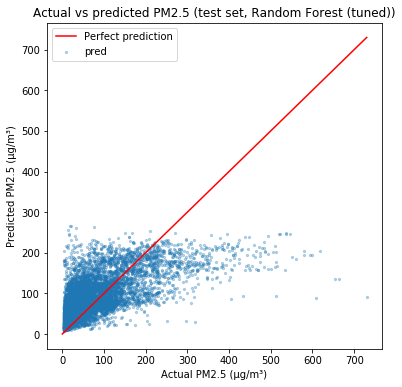

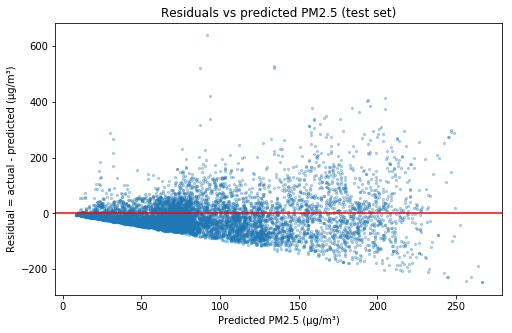

In [37]:
final_model = all_models[final_name]
pred = final_model.predict(X_test)

res = pd.DataFrame({'actual': y_test.values, 'pred': pred,
                    'station': test_m['station'].values, 'month': test_m['month'].values})
res['resid'] = res['actual'] - res['pred']

print("Share of negative predictions:", round((res['pred'] < 0).mean() * 100, 2), "%")

idx = np.random.RandomState(SEED).choice(len(res), 8000, replace=False)
s = res.iloc[idx]

plt.figure(figsize=(6, 6))
plt.scatter(s['actual'], s['pred'], s=5, alpha=0.3)
lim = [0, s['actual'].max()]
plt.plot(lim, lim, color='red', label='Perfect prediction')
plt.title('Actual vs predicted PM2.5 (test set, ' + final_name + ')')
plt.xlabel('Actual PM2.5 (µg/m³)')
plt.ylabel('Predicted PM2.5 (µg/m³)')
plt.legend()
plt.savefig('actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(s['pred'], s['resid'], s=5, alpha=0.3)
plt.axhline(0, color='red')
plt.title('Residuals vs predicted PM2.5 (test set)')
plt.xlabel('Predicted PM2.5 (µg/m³)')
plt.ylabel('Residual = actual - predicted (µg/m³)')
plt.savefig('residual_plot.png', dpi=150, bbox_inches='tight')
plt.show()

In [38]:
bins = [-0.1, 35, 75, 150, 250, np.inf]
labels = ['0-35', '35-75', '75-150', '150-250', '250+']
res['range'] = pd.cut(res['actual'], bins=bins, labels=labels)
res['abs_err'] = res['resid'].abs()

g = res.groupby('range')
by_range = pd.DataFrame({
    'hours': g.size(),
    'MAE': g['abs_err'].mean(),
    'mean_resid': g['resid'].mean(),
    'resid_std': g['resid'].std()
}).round(1)
print(by_range)

print(res.groupby('month')['abs_err'].mean().round(1))
print(res.groupby('station')['abs_err'].mean().sort_values().round(1))

         hours    MAE  mean_resid  resid_std
range                                       
0-35     39734   38.7       -38.5       31.4
35-75    24968   35.7       -30.9       36.2
75-150   23305   33.6        -1.3       42.3
150-250  10001   54.5        45.4       49.8
250+      4745  167.3       167.3       88.2
month
1     63.7
2     54.2
3     47.1
4     30.2
5     34.4
6     29.4
7     37.8
8     34.6
9     39.9
10    50.4
11    45.5
12    63.5
Name: abs_err, dtype: float64
station
Changping        40.6
Dingling         41.8
Guanyuan         43.8
Tiantan          44.1
Aotizhongxin     44.3
Huairou          44.6
Gucheng          44.8
Nongzhanguan     44.8
Dongsi           45.3
Shunyi           45.3
Wanshouxigong    46.0
Wanliu           46.2
Name: abs_err, dtype: float64


Baseline validation R2 on this sample: 0.37
DEWP                 0.8365
month_cos            0.3412
is_heating_season    0.1959
month_sin            0.1839
TEMP                 0.0734
PRES                 0.0319
WSPM                 0.0299
hour_sin             0.0064
hour_cos             0.0033
wd                   0.0019
RAIN                 0.0007
station              0.0001
dayofweek           -0.0132
dtype: float64


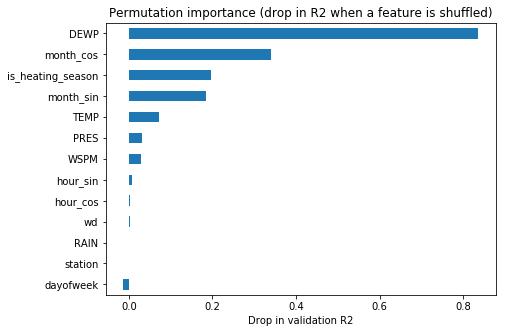

In [39]:
from sklearn.metrics import r2_score

sub = X_val.sample(20000, random_state=SEED)
y_sub = y_val.loc[sub.index]
rng = np.random.RandomState(SEED)

base = r2_score(y_sub, final_model.predict(sub))
print("Baseline validation R2 on this sample:", round(base, 3))

drops = {}
for col in sub.columns:
    scores = []
    for _ in range(3):
        shuffled = sub.copy()
        shuffled[col] = rng.permutation(shuffled[col].values)
        scores.append(r2_score(y_sub, final_model.predict(shuffled)))
    drops[col] = base - np.mean(scores)

imp = pd.Series(drops).sort_values(ascending=False)
print(imp.round(4))

plt.figure(figsize=(7, 5))
imp.sort_values().plot(kind='barh')
plt.title('Permutation importance (drop in R2 when a feature is shuffled)')
plt.xlabel('Drop in validation R2')
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

## Written reflection (D5)

**1. Which variables or patterns were most strongly associated with PM2.5?**
At the Aotizhongxin station, PM2.5 was most strongly correlated with other pollutants: PM10 (r = 0.88), CO (0.79) and NO2 (0.68), which share emission sources. Among the variables available for prediction, the meteorological association was much weaker (wind speed r = -0.28, meaning more wind goes with less pollution). Across all stations PM2.5 showed a clear seasonal pattern, and permutation importance showed that month and the temperature-related variables (TEMP, DEWP, PRES) carried most of the model's predictive information, while hour, wind, rain and station added little.

**2. Which model performed best on held-out data, and why was it selected?**
Linear Regression performed best, with a test RMSE of 65.46 µg/m³, MAE of 47.33 and R² of 0.374, compared with a mean-only baseline RMSE of 82.94 and R² of about 0. I selected it because it had the lowest validation RMSE (the rule was fixed before scoring the test set), and because Ridge, Lasso, the Decision Tree and the Random Forest were within about 1.5 µg/m³ RMSE of it, so the simplest and most interpretable model was the sensible choice. The Random Forest also overfit clearly (train R² 0.78 vs validation 0.31).

**3. What did the residual analysis reveal about the model's errors?**
The model systematically underpredicts high-pollution hours: predictions flatten at roughly 150-200 µg/m³ even when actual PM2.5 reaches 400-700, so the largest residuals are large positive values. The residual spread grows with the predicted level (heteroscedasticity), and some predictions are negative, which is physically impossible and reflects the linear form of the model. These patterns show that weather and calendar variables alone cannot anticipate pollution episodes.

**4. How did handling of missing values and outliers affect the analysis?**
Rows with a missing PM2.5 target were removed (about 2-3% per station), and missing predictor values were filled with the training-set median (or most frequent category for wind direction), fitted on training data only so no information leaked from validation or test. For outliers, the IQR rule flagged 1,624 PM2.5 observations (fence 252 µg/m³) and the Z-score rule flagged 591 (threshold about 329 µg/m³), the difference arising because the data is right-skewed. I retained them because they are plausible pollution episodes, and removing them would have hidden exactly the events the model should predict, at the cost of larger RMSE.

**5. What is one important limitation of the predictions, and how would it be addressed?**
The models have no information about the pollution already in the air: they use only same-hour weather and calendar features, so R² is limited to about 0.37 and spikes are missed. This would be addressed by adding lagged and rolling-mean PM2.5 features (using only past values, computed per station), evaluated with chronological cross-validation. A related limitation is that same-hour weather is assumed to be available at prediction time, for example from a weather forecast.